# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [ ]:
DATA_PATH = Path("/content/wine.csv")

df = pd.read_csv(DATA_PATH)

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
# Revisamos las características básicas del dataset.
print('Filas y columnas:', df.shape)
print('\nTipos de datos:')
print(df.dtypes)
print('\nValores faltantes por columna:')
print(df.isnull().sum())
print('\nTotal de filas duplicadas:', df.duplicated().sum())
print('\nDistribución de la variable objetivo:')
print(df['target'].value_counts().sort_index())
print('\nPorcentaje por clase:')
print((df['target'].value_counts(normalize=True).sort_index() * 100).round(2))

# Comprobamos que estén los campos que necesita el ejercicio.
assert 'target' in df.columns, 'No existe la columna target'
assert df['target'].nunique() >= 2, 'Se necesitan al menos dos clases'

Filas y columnas: (178, 14)

Tipos de datos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Valores faltantes por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue      

**Conclusión de calidad:**

> El archivo original contiene 178 observaciones, 13 características numéricas y la variable objetivo target. No presenta valores faltantes ni filas duplicadas, por lo que no se requiere eliminar o imputar registros en esta etapa. Las clases están distribuidas en 59 registros de clase 0, 71 de clase 1 y 48 de clase 2. Como las proporciones son distintas, conviene realizar un split estratificado.

## 2. Split train/test

In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['target'],
    random_state=RANDOM_STATE
)

print('Total:', len(df))
print('Entrenamiento:', len(train_df))
print('Prueba:', len(test_df))
print('\nDistribución de clases en entrenamiento:')
print(train_df['target'].value_counts().sort_index())

Total: 178
Entrenamiento: 142
Prueba: 36

Distribución de clases en entrenamiento:
target
0    47
1    57
2    38
Name: count, dtype: int64


In [ ]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

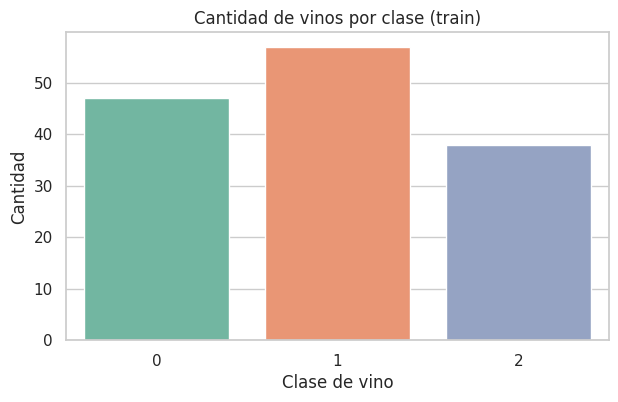

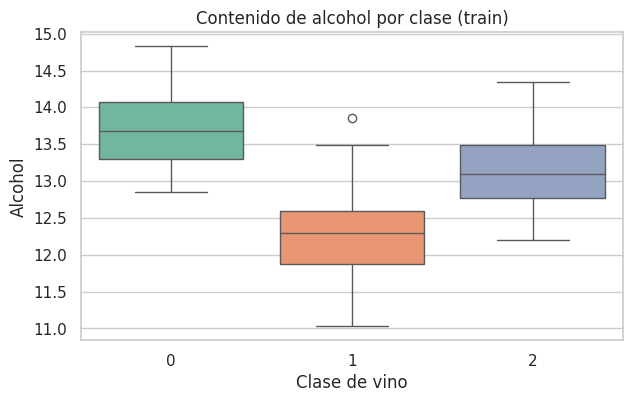

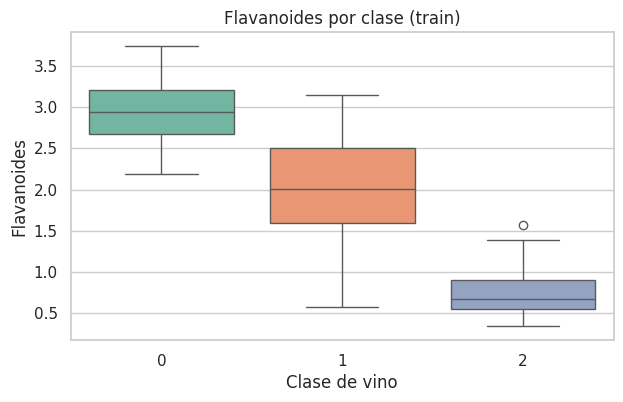

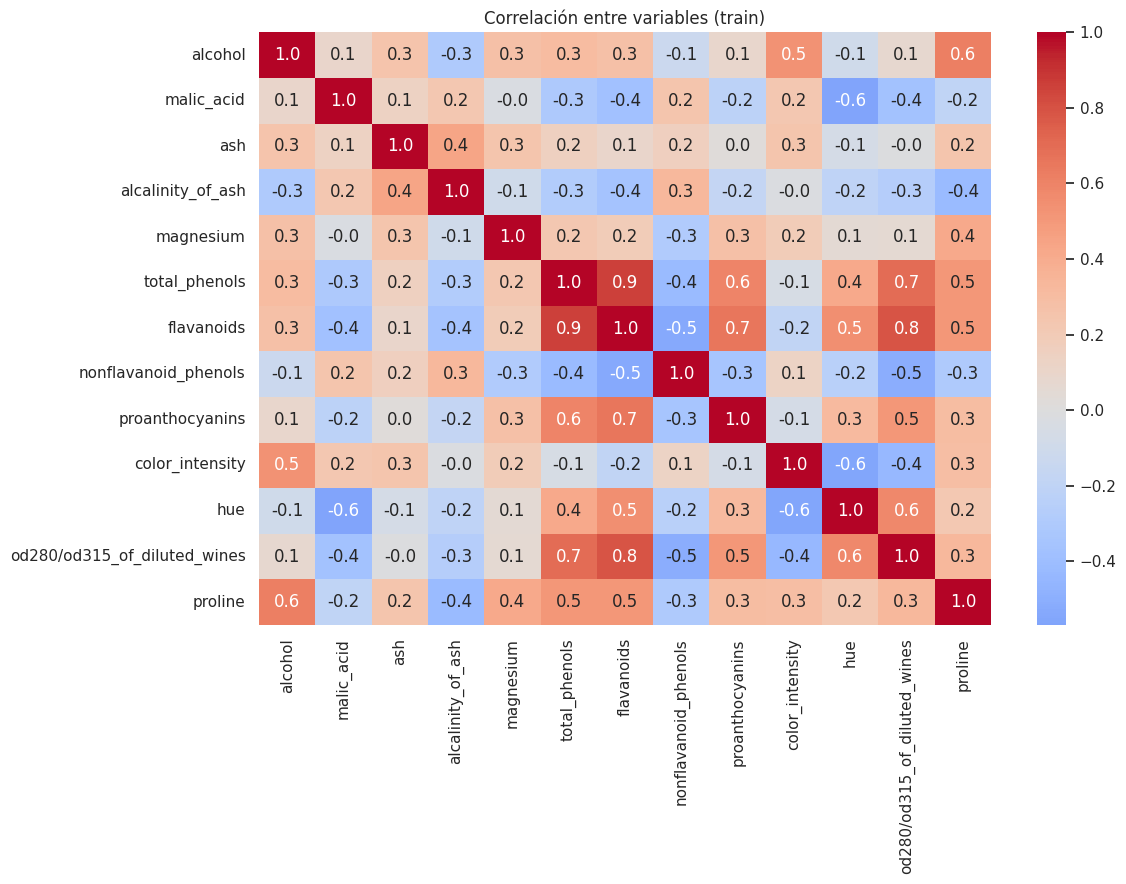


Medianas de alcohol y flavanoides por clase:
        alcohol  flavanoids
target                     
0         13.68        2.94
1         12.29        2.01
2         13.10        0.68

Correlaciones absolutas más altas entre variables diferentes:
total_phenols  flavanoids                      0.861
flavanoids     od280/od315_of_diluted_wines    0.786
total_phenols  od280/od315_of_diluted_wines    0.695
flavanoids     proanthocyanins                 0.657
alcohol        proline                         0.621
dtype: float64


In [ ]:
# EDA: únicamente con train_df; no usamos test_df.
sns.set_theme(style='whitegrid')

# Gráfico 1: cantidad de vinos por clase.
plt.figure(figsize=(7, 4))
sns.countplot(data=train_df, x='target', hue='target', palette='Set2', legend=False)
plt.title('Cantidad de vinos por clase (train)')
plt.xlabel('Clase de vino')
plt.ylabel('Cantidad')
plt.show()

# Gráfico 2: distribución del alcohol según la clase.
plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x='target', y='alcohol', hue='target', palette='Set2', legend=False)
plt.title('Contenido de alcohol por clase (train)')
plt.xlabel('Clase de vino')
plt.ylabel('Alcohol')
plt.show()

# Gráfico 3: relación entre flavanoides y la clase.
plt.figure(figsize=(7, 4))
sns.boxplot(data=train_df, x='target', y='flavanoids', hue='target', palette='Set2', legend=False)
plt.title('Flavanoides por clase (train)')
plt.xlabel('Clase de vino')
plt.ylabel('Flavanoides')
plt.show()

# Gráfico 4: correlación entre las variables predictoras.
plt.figure(figsize=(12, 9))
correlaciones = train_df.drop(columns=['target']).corr()
sns.heatmap(correlaciones, cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title('Correlación entre variables (train)')
plt.tight_layout()
plt.show()

# Valores que permiten redactar los hallazgos a partir de train.
print('\nMedianas de alcohol y flavanoides por clase:')
print(train_df.groupby('target')[['alcohol', 'flavanoids']].median().round(2))
print('\nCorrelaciones absolutas más altas entre variables diferentes:')
corr_abs = correlaciones.abs()
pares = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool)).stack()
print(pares.sort_values(ascending=False).head(5).round(3))

**Hallazgos:**

1. **Distribución de clases:** las tres clases están representadas, pero no contienen exactamente la misma cantidad de vinos. Por eso usamos stratify en la separación y más adelante conviene comparar métricas como F1 macro, además de accuracy.
2. **Variables químicas:** los diagramas de caja de alcohol y flavanoids permiten observar diferencias entre clases. Esto sugiere que estas variables podrían aportar información para clasificar vinos, aunque debemos verificarlo durante el entrenamiento.
3. **Correlaciones:** algunas variables químicas están correlacionadas. Esto puede ser relevante para modelos sensibles a relaciones entre características; por tanto, en el siguiente challenge compararemos distintos algoritmos y aplicaremos estandarización cuando corresponda.



## 4. Persistencia de datos y contrato

In [ ]:
# Se reinician los índices para guardar CSV limpios, sin una columna extra de índice.
train_guardar = train_df.reset_index(drop=True)
test_guardar = test_df.reset_index(drop=True)
train_guardar.to_csv(PROCESSED_DATA_DIR / 'train.csv', index=False)
test_guardar.to_csv(PROCESSED_DATA_DIR / 'test.csv', index=False)

# Contrato de datos para que el siguiente challenge conozca las columnas.
contrato = {
    'target': 'target',
    'features': [col for col in df.columns if col != 'target'],
    'random_state': RANDOM_STATE,
    'test_size': 0.20
}
with open(ARTIFACTS_DIR / 'data_contract.json', 'w', encoding='utf-8') as f:
    json.dump(contrato, f, indent=4, ensure_ascii=False)

print('Archivos creados:')
print(PROCESSED_DATA_DIR / 'train.csv')
print(PROCESSED_DATA_DIR / 'test.csv')
print(ARTIFACTS_DIR / 'data_contract.json')
print('\nContrato:')
print(json.dumps(contrato, indent=2, ensure_ascii=False))

Archivos creados:
/content/data/processed/train.csv
/content/data/processed/test.csv
/content/artifacts/data_contract.json

Contrato:
{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2
}


In [ ]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.

In [ ]:
from google.colab import files
from zipfile import ZipFile
from pathlib import Path

# Crear un ZIP con los resultados del Challenge 1
ZIP_PATH = Path('/content/challenge_1_resultados.zip')

with ZipFile(ZIP_PATH, 'w') as zip_file:
    zip_file.write(
        PROCESSED_DATA_DIR / 'train.csv',
        'data/processed/train.csv'
    )
    zip_file.write(
        PROCESSED_DATA_DIR / 'test.csv',
        'data/processed/test.csv'
    )
    zip_file.write(
        ARTIFACTS_DIR / 'data_contract.json',
        'artifacts/data_contract.json'
    )

# Descargar el ZIP al computador
files.download(str(ZIP_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>